In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [111]:
df = pd.read_csv('/Users/amaree/Downloads/FRSC RTC Report 1960-2024 UD.csv')

df.head()

,Year,Fatal Cases,Serious Cases,Minor Cases,Total Cases,Persons Killed,Persons Injured,Total Casualty
0,1960,826,9065,4239,14130,1083,10216,11299
1,1961,193,9982,5788,15963,1313,10614,11927
2,1962,1263,9159,5895,16317,1578,10341,11919
3,1963,967,6918,11950,19835,1532,7771,9303
4,1964,911,7371,7645,15927,1769,12581,14350


In [112]:
numeric_cols = [
    "Fatal Cases",
    "Serious Cases",
    "Minor Cases",
    "Total Cases",
    "Persons Killed",
    "Persons Injured",
    "Total Casualty"
]

for col in numeric_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

df["Year"] = df["Year"].astype(int)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             65 non-null     int64  
 1   Fatal Cases      65 non-null     float64
 2   Serious Cases    65 non-null     float64
 3   Minor Cases      65 non-null     float64
 4   Total Cases      65 non-null     float64
 5   Persons Killed   65 non-null     float64
 6   Persons Injured  65 non-null     float64
 7   Total Casualty   65 non-null     float64
dtypes: float64(7), int64(1)
memory usage: 4.2 KB


In [113]:
extended_df = pd.read_csv('/Users/amaree/Downloads/FRSC RTC Report 1960-2024 UD.csv')

extended_df.head()

,Year,Fatal Cases,Serious Cases,Minor Cases,Total Cases,Persons Killed,Persons Injured,Total Casualty
0,1960,826,9065,4239,14130,1083,10216,11299
1,1961,193,9982,5788,15963,1313,10614,11927
2,1962,1263,9159,5895,16317,1578,10341,11919
3,1963,967,6918,11950,19835,1532,7771,9303
4,1964,911,7371,7645,15927,1769,12581,14350


### Machine Learning Forecasting Using the Annual National Dataset

Following the evaluation of the ARIMA models, Linear Regression, Random Forest and Gradient Boosting were applied to the same annual national road traffic crash dataset.

To ensure a fair comparison, the machine-learning models were evaluated using the same expanding-window one-year-ahead forecasting approach for the 2014–2024 period. For each year, the models were trained using only the observations available before the forecast year.

Unlike ARIMA, machine-learning regression models require input features to generate predictions. Lagged variables were therefore created using historical crash figures, allowing the models to predict the following year's crash count based on previous observations without using future information.

The machine-learning models used three input features:

Lag 1: The number of crash cases recorded in the previous year.

Lag 2: The number of crash cases recorded two years earlier.

Time trend: A variable representing the progression of time across the historical dataset.

The same forecasting period and evaluation metrics, including MAE, RMSE and MAPE, were retained to allow direct comparison with the ARIMA models and naïve benchmark.

In [115]:
# Create a separate dataframe for annual machine-learning analysis
ml_annual = extended_df.copy()

outcomes = [
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases",
    "Total Cases"
]

# Create Lag 1 and Lag 2 for each outcome
for outcome in outcomes:
    ml_annual[f"{outcome}_Lag1"] = ml_annual[outcome].shift(1)
    ml_annual[f"{outcome}_Lag2"] = ml_annual[outcome].shift(2)

# Create a simple chronological trend variable
ml_annual["Trend"] = np.arange(len(ml_annual))

ml_annual.tail(10)

,Year,Fatal Cases,Serious Cases,Minor Cases,Total Cases,Persons Killed,Persons Injured,Total Casualty,Minor Cases_Lag1,Minor Cases_Lag2,Serious Cases_Lag1,Serious Cases_Lag2,Fatal Cases_Lag1,Fatal Cases_Lag2,Total Cases_Lag1,Total Cases_Lag2,Trend
55,2015,2854,6039,841,9734,5440,30478,35918,907.0,1700.0,6356.0,8589.0,3117,"3,294",10380.0,13583.0,55
56,2016,2638,5633,1423,9694,5053,30105,35158,841.0,907.0,6039.0,6356.0,2854,3117,9734.0,10380.0,56
57,2017,2587,5456,1340,9383,5121,31094,36215,1423.0,841.0,5633.0,6039.0,2638,2854,9694.0,9734.0,57
58,2018,2739,5849,1153,9741,5181,32220,37401,1340.0,1423.0,5456.0,5633.0,2587,2638,9383.0,9694.0,58
59,2019,2896,6911,1265,11072,5483,35981,41464,1153.0,1340.0,5849.0,5456.0,2739,2587,9741.0,9383.0,59
60,2020,2961,7567,1347,11875,5574,33311,38885,1265.0,1153.0,6911.0,5849.0,2896,2739,11072.0,9741.0,60
61,2021,3218,8324,1485,13027,6205,38073,44278,1347.0,1265.0,7567.0,6911.0,2961,2896,11875.0,11072.0,61
62,2022,3309,8953,1394,13656,6456,38930,45386,1485.0,1347.0,8324.0,7567.0,3218,2961,13027.0,11875.0,62
63,2023,2652,6924,1041,10617,5081,31874,36955,1394.0,1485.0,8953.0,8324.0,3309,3218,13656.0,13027.0,63
64,2024,2532,6131,907,9570,5421,31154,36575,1041.0,1394.0,6924.0,8953.0,2652,3309,10617.0,13656.0,64


In [116]:
# check constructed data

ml_annual[
    [
        "Year",
        "Total Cases",
        "Total Cases_Lag1",
        "Total Cases_Lag2",
        "Trend"
    ]
].tail(15)

,Year,Total Cases,Total Cases_Lag1,Total Cases_Lag2,Trend
50,2010,11385,10854.0,11341.0,50
51,2011,13196,11385.0,10854.0,51
52,2012,13262,13196.0,11385.0,52
53,2013,13583,13262.0,13196.0,53
54,2014,10380,13583.0,13262.0,54
55,2015,9734,10380.0,13583.0,55
56,2016,9694,9734.0,10380.0,56
57,2017,9383,9694.0,9734.0,57
58,2018,9741,9383.0,9694.0,58
59,2019,11072,9741.0,9383.0,59


### Rolling Linear Regression

What Linear Regression will do
for each outcome, essentially asking the model to learn a relationship like:
Next year's cases = relationship with last year's cases + relationship with cases two years ago + long-term time trend
For Total Cases, conceptually:
$$ Total_t = \beta_0 + \beta_1(Total_{t-1}) + \beta_2(Total_{t-2}) + \beta_3(Trend_t) $$


#### Rolling Linear Regression Forecasting

Linear Regression was first evaluated as the baseline machine-learning model for forecasting annual road traffic crash cases. For each crash category, the model used three input features: the number of cases recorded in the previous year (Lag 1), the number recorded two years earlier (Lag 2), and a time trend representing the progression of the historical series.

The model was used to examine the relationship between these features and the following year's crash count, allowing predictions to be generated from historical patterns.

To maintain consistency with the ARIMA analysis, an expanding-window one-year-ahead forecasting approach was applied over the 2014–2024 period. For each forecast year, the Linear Regression model was trained using only observations available before that year, ensuring that the actual value being predicted was not included in the training data.

This approach allowed the forecasting accuracy of Linear Regression to be compared directly with the ARIMA models and naïve benchmark using the same evaluation period and performance metrics.

In [119]:
# create the rolling linear regression function

from sklearn.linear_model import LinearRegression

def rolling_linear_regression(data, outcome, start_year=2014, end_year=2024):

    lag1 = f"{outcome}_Lag1"
    lag2 = f"{outcome}_Lag2"

    features = [lag1, lag2, "Trend"]

    results = []

    for forecast_year in range(start_year, end_year + 1):

        # Training data: only years BEFORE the forecast year
        train = data[
            data["Year"] < forecast_year
        ].dropna(subset=features + [outcome])

        # The year we want to predict
        test = data[
            data["Year"] == forecast_year
        ].dropna(subset=features + [outcome])

        X_train = train[features]
        y_train = train[outcome]

        X_test = test[features]
        y_actual = test[outcome].iloc[0]

        # Fit Linear Regression
        model = LinearRegression()
        model.fit(X_train, y_train)

        # Produce one-year-ahead forecast
        forecast = model.predict(X_test)[0]

        error = y_actual - forecast

        results.append({
            "Year": forecast_year,
            "Actual": y_actual,
            "Forecast": forecast,
            "Error": error,
            "Absolute_Error": abs(error),
            "APE": abs(error / y_actual) * 100
        })

    return pd.DataFrame(results)

In [120]:
case_columns = [
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases",
    "Total Cases"
]

for column in case_columns:
    extended_df[column] = pd.to_numeric(
        extended_df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# Check the result
extended_df[case_columns].dtypes

Minor Cases      int64
Serious Cases    int64
Fatal Cases      int64
Total Cases      int64
dtype: object

In [121]:
# Convert accident-count columns to numeric

case_columns = [
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases",
    "Total Cases"
]

for col in case_columns:
    ml_annual[col] = pd.to_numeric(
        ml_annual[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# Check data types
ml_annual[case_columns].dtypes

Minor Cases      int64
Serious Cases    int64
Fatal Cases      int64
Total Cases      int64
dtype: object

In [122]:
outcomes = [
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases",
    "Total Cases"
]

for outcome in outcomes:
    ml_annual[f"{outcome}_Lag1"] = ml_annual[outcome].shift(1)
    ml_annual[f"{outcome}_Lag2"] = ml_annual[outcome].shift(2)

# Check
ml_annual.tail(15)

,Year,Fatal Cases,Serious Cases,Minor Cases,Total Cases,Persons Killed,Persons Injured,Total Casualty,Minor Cases_Lag1,Minor Cases_Lag2,Serious Cases_Lag1,Serious Cases_Lag2,Fatal Cases_Lag1,Fatal Cases_Lag2,Total Cases_Lag1,Total Cases_Lag2,Trend
50,2010,2388,6815,2182,11385,6052,35691,41743,2370.0,2646.0,6024.0,5671.0,2460.0,3024.0,10854.0,11341.0,50
51,2011,2840,8357,1999,13196,6054,41165,47219,2182.0,2370.0,6815.0,6024.0,2388.0,2460.0,11385.0,10854.0,51
52,2012,2935,8277,2050,13262,6092,39348,45440,1999.0,2182.0,8357.0,6815.0,2840.0,2388.0,13196.0,11385.0,52
53,2013,3294,8589,1700,13583,6544,40057,46601,2050.0,1999.0,8277.0,8357.0,2935.0,2840.0,13262.0,13196.0,53
54,2014,3117,6356,907,10380,5996,32063,38059,1700.0,2050.0,8589.0,8277.0,3294.0,2935.0,13583.0,13262.0,54
55,2015,2854,6039,841,9734,5440,30478,35918,907.0,1700.0,6356.0,8589.0,3117.0,3294.0,10380.0,13583.0,55
56,2016,2638,5633,1423,9694,5053,30105,35158,841.0,907.0,6039.0,6356.0,2854.0,3117.0,9734.0,10380.0,56
57,2017,2587,5456,1340,9383,5121,31094,36215,1423.0,841.0,5633.0,6039.0,2638.0,2854.0,9694.0,9734.0,57
58,2018,2739,5849,1153,9741,5181,32220,37401,1340.0,1423.0,5456.0,5633.0,2587.0,2638.0,9383.0,9694.0,58
59,2019,2896,6911,1265,11072,5483,35981,41464,1153.0,1340.0,5849.0,5456.0,2739.0,2587.0,9741.0,9383.0,59


In [123]:
# run linear regression for all four outcomes

lr_results_list = []

for outcome in outcomes:

    result = rolling_linear_regression(
        data=ml_annual,
        outcome=outcome,
        start_year=2014,
        end_year=2024
    )

    result["Outcome"] = outcome
    result["Model"] = "Linear Regression"

    lr_results_list.append(result)

lr_results = pd.concat(
    lr_results_list,
    ignore_index=True
)

lr_results.round(2)

,Year,Actual,Forecast,Error,Absolute_Error,APE,Outcome,Model
0,2014,907,1201.22,-294.22,294.22,32.44,Minor Cases,Linear Regression
1,2015,841,578.34,262.66,262.66,31.23,Minor Cases,Linear Regression
2,2016,1423,249.52,1173.48,1173.48,82.46,Minor Cases,Linear Regression
3,2017,1340,588.73,751.27,751.27,56.06,Minor Cases,Linear Regression
4,2018,1153,742.84,410.16,410.16,35.57,Minor Cases,Linear Regression
5,2019,1265,595.77,669.23,669.23,52.90,Minor Cases,Linear Regression
6,2020,1347,598.66,748.34,748.34,55.56,Minor Cases,Linear Regression
7,2021,1485,687.36,797.64,797.64,53.71,Minor Cases,Linear Regression
8,2022,1394,801.03,592.97,592.97,42.54,Minor Cases,Linear Regression
9,2023,1041,791.38,249.62,249.62,23.98,Minor Cases,Linear Regression


In [124]:
lr_summary = (
    lr_results
    .groupby(["Outcome", "Model"])
    .apply(
        lambda x: pd.Series({
            "MAE": x["Absolute_Error"].mean(),
            "RMSE": np.sqrt((x["Error"] ** 2).mean()),
            "MAPE (%)": x["APE"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

lr_summary.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,Linear Regression,276.81,354.12,10.09
1,Minor Cases,Linear Regression,574.19,636.58,46.08
2,Serious Cases,Linear Regression,1091.25,1201.73,16.07
3,Total Cases,Linear Regression,1541.79,1681.11,13.97


### Random Forest Test

In [126]:
from sklearn.ensemble import RandomForestRegressor

def rolling_random_forest(data, outcome, start_year=2014, end_year=2024):

    results = []

    lag1 = f"{outcome}_Lag1"
    lag2 = f"{outcome}_Lag2"

    features = [lag1, lag2, "Trend"]

    for year in range(start_year, end_year + 1):

        # Expanding training window
        train = data[data["Year"] < year].dropna(
            subset=features + [outcome]
        )

        # Current year to forecast
        test = data[data["Year"] == year].dropna(
            subset=features + [outcome]
        )

        if len(test) == 0:
            continue

        X_train = train[features]
        y_train = train[outcome]

        X_test = test[features]
        y_actual = test[outcome].iloc[0]

        # Random Forest model
        model = RandomForestRegressor(
            n_estimators=500,
            max_depth=3,
            min_samples_leaf=2,
            random_state=42
        )

        model.fit(X_train, y_train)

        forecast = model.predict(X_test)[0]

        results.append({
            "Year": year,
            "Actual": y_actual,
            "Forecast": forecast,
            "Error": y_actual - forecast,
            "Absolute_Error": abs(y_actual - forecast),
            "APE": abs((y_actual - forecast) / y_actual) * 100
        })

    return pd.DataFrame(results)

In [127]:
rf_results_list = []

for outcome in outcomes:

    result = rolling_random_forest(
        data=ml_annual,
        outcome=outcome,
        start_year=2014,
        end_year=2024
    )

    result["Outcome"] = outcome
    result["Model"] = "Random Forest"

    rf_results_list.append(result)

rf_results = pd.concat(
    rf_results_list,
    ignore_index=True
)

rf_results.round(2)

,Year,Actual,Forecast,Error,Absolute_Error,APE,Outcome,Model
0,2014,907,2074.58,-1167.58,1167.58,128.73,Minor Cases,Random Forest
1,2015,841,1876.36,-1035.36,1035.36,123.11,Minor Cases,Random Forest
2,2016,1423,1645.11,-222.11,222.11,15.61,Minor Cases,Random Forest
3,2017,1340,1635.85,-295.85,295.85,22.08,Minor Cases,Random Forest
4,2018,1153,1567.63,-414.63,414.63,35.96,Minor Cases,Random Forest
5,2019,1265,1497.23,-232.23,232.23,18.36,Minor Cases,Random Forest
6,2020,1347,1459.66,-112.66,112.66,8.36,Minor Cases,Random Forest
7,2021,1485,1438.88,46.12,46.12,3.11,Minor Cases,Random Forest
8,2022,1394,1497.40,-103.40,103.40,7.42,Minor Cases,Random Forest
9,2023,1041,1431.57,-390.57,390.57,37.52,Minor Cases,Random Forest


In [128]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_summary = (
    rf_results
    .groupby(["Outcome", "Model"])
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["Actual"],
                x["Forecast"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["Actual"],
                    x["Forecast"]
                )
            ),
            "MAPE (%)": x["APE"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

rf_summary.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,Random Forest,214.80,243.39,7.39
1,Minor Cases,Random Forest,409.82,540.51,41.27
2,Serious Cases,Random Forest,891.78,995.27,13.12
3,Total Cases,Random Forest,1259.58,1338.69,11.77


### Gradient Boosting Test

In [130]:
from sklearn.ensemble import GradientBoostingRegressor

def rolling_gradient_boosting(data, outcome, start_year=2014, end_year=2024):

    results = []

    lag1 = f"{outcome}_Lag1"
    lag2 = f"{outcome}_Lag2"

    features = [lag1, lag2, "Trend"]

    for year in range(start_year, end_year + 1):

        # Expanding training window
        train = data[data["Year"] < year].dropna(
            subset=features + [outcome]
        )

        # Current year to forecast
        test = data[data["Year"] == year].dropna(
            subset=features + [outcome]
        )

        if len(test) == 0:
            continue

        X_train = train[features]
        y_train = train[outcome]

        X_test = test[features]
        y_actual = test[outcome].iloc[0]

        # Gradient Boosting model
        model = GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=2,
            random_state=42
        )

        model.fit(X_train, y_train)

        forecast = model.predict(X_test)[0]

        results.append({
            "Year": year,
            "Actual": y_actual,
            "Forecast": forecast,
            "Error": y_actual - forecast,
            "Absolute_Error": abs(y_actual - forecast),
            "APE": abs((y_actual - forecast) / y_actual) * 100
        })

    return pd.DataFrame(results)

In [131]:
gb_results_list = []

for outcome in outcomes:

    result = rolling_gradient_boosting(
        data=ml_annual,
        outcome=outcome,
        start_year=2014,
        end_year=2024
    )

    result["Outcome"] = outcome
    result["Model"] = "Gradient Boosting"

    gb_results_list.append(result)

gb_results = pd.concat(
    gb_results_list,
    ignore_index=True
)

gb_results.round(2)

,Year,Actual,Forecast,Error,Absolute_Error,APE,Outcome,Model
0,2014,907,2224.67,-1317.67,1317.67,145.28,Minor Cases,Gradient Boosting
1,2015,841,1936.94,-1095.94,1095.94,130.31,Minor Cases,Gradient Boosting
2,2016,1423,1480.31,-57.31,57.31,4.03,Minor Cases,Gradient Boosting
3,2017,1340,1566.75,-226.75,226.75,16.92,Minor Cases,Gradient Boosting
4,2018,1153,1605.44,-452.44,452.44,39.24,Minor Cases,Gradient Boosting
5,2019,1265,1543.44,-278.44,278.44,22.01,Minor Cases,Gradient Boosting
6,2020,1347,1488.15,-141.15,141.15,10.48,Minor Cases,Gradient Boosting
7,2021,1485,1519.91,-34.91,34.91,2.35,Minor Cases,Gradient Boosting
8,2022,1394,1549.21,-155.21,155.21,11.13,Minor Cases,Gradient Boosting
9,2023,1041,1544.32,-503.32,503.32,48.35,Minor Cases,Gradient Boosting


In [132]:
gb_summary = (
    gb_results
    .groupby(["Outcome", "Model"])
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["Actual"],
                x["Forecast"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["Actual"],
                    x["Forecast"]
                )
            ),
            "MAPE (%)": x["APE"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

gb_summary.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,Gradient Boosting,149.50,179.00,5.26
1,Minor Cases,Gradient Boosting,438.28,594.22,44.69
2,Serious Cases,Gradient Boosting,998.80,1137.27,14.90
3,Total Cases,Gradient Boosting,1209.94,1330.91,11.51


In [133]:
naive_results_list = []

for outcome in outcomes:

    temp = ml_annual[
        (ml_annual["Year"] >= 2014) &
        (ml_annual["Year"] <= 2024)
    ].copy()

    temp["Actual"] = temp[outcome]
    temp["Forecast"] = temp[f"{outcome}_Lag1"]

    temp["Error"] = temp["Actual"] - temp["Forecast"]
    temp["Absolute_Error"] = abs(temp["Error"])
    temp["APE"] = (
        temp["Absolute_Error"] / temp["Actual"]
    ) * 100

    temp["Outcome"] = outcome
    temp["Model"] = "Naive Previous-Year"

    naive_results_list.append(
        temp[
            [
                "Year",
                "Actual",
                "Forecast",
                "Error",
                "Absolute_Error",
                "APE",
                "Outcome",
                "Model"
            ]
        ]
    )

naive_results = pd.concat(
    naive_results_list,
    ignore_index=True
)

In [134]:
naive_summary = (
    naive_results
    .groupby(["Outcome", "Model"])
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["Actual"],
                x["Forecast"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["Actual"],
                    x["Forecast"]
                )
            ),
            "MAPE (%)": x["APE"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

naive_summary.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,Naive Previous-Year,200.55,256.22,7.13
1,Minor Cases,Naive Previous-Year,238.27,330.69,21.64
2,Serious Cases,Naive Previous-Year,859.27,1074.92,12.72
3,Total Cases,Naive Previous-Year,1141.73,1518.79,10.61


In [135]:
# define Sanusi's ARIMA order

sanusi_orders = {
    "Minor Cases": (1, 1, 1),
    "Serious Cases": (1, 1, 0),
    "Fatal Cases": (0, 1, 1),
    "Total Cases": (1, 1, 1)
}

In [136]:
# create rolling ARIMA fn

from statsmodels.tsa.arima.model import ARIMA

def rolling_arima(data, outcome, order, start_year=2014, end_year=2024):

    results = []

    for year in range(start_year, end_year + 1):

        # Expanding training window: all observations before forecast year
        train = data[
            data["Year"] < year
        ][outcome].dropna()

        # Actual value for forecast year
        test = data[
            data["Year"] == year
        ]

        if len(test) == 0:
            continue

        y_actual = test[outcome].iloc[0]

        # Fit ARIMA using all information available before that year
        model = ARIMA(
            train,
            order=order
        )

        fitted_model = model.fit()

        # One-year-ahead forecast
        forecast = fitted_model.forecast(steps=1).iloc[0]

        results.append({
            "Year": year,
            "Actual": y_actual,
            "Forecast": forecast,
            "Error": y_actual - forecast,
            "Absolute_Error": abs(y_actual - forecast),
            "APE": abs((y_actual - forecast) / y_actual) * 100
        })

    return pd.DataFrame(results)

In [137]:
# run all 4 Sanusi models

sanusi_arima_results_list = []

for outcome, order in sanusi_orders.items():

    result = rolling_arima(
        data=ml_annual,
        outcome=outcome,
        order=order,
        start_year=2014,
        end_year=2024
    )

    result["Outcome"] = outcome
    result["Model"] = f"Sanusi ARIMA{order}"

    sanusi_arima_results_list.append(result)

sanusi_arima_results = pd.concat(
    sanusi_arima_results_list,
    ignore_index=True
)

sanusi_arima_results.round(2)

,Year,Actual,Forecast,Error,Absolute_Error,APE,Outcome,Model
0,2014,907,1804.77,-897.77,897.77,98.98,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
1,2015,841,1056.25,-215.25,215.25,25.59,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
2,2016,1423,789.13,633.87,633.87,44.54,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
3,2017,1340,1302.54,37.46,37.46,2.80,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
4,2018,1153,1415.90,-262.90,262.90,22.80,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
5,2019,1265,1164.44,100.56,100.56,7.95,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
6,2020,1347,1231.96,115.04,115.04,8.54,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
7,2021,1485,1341.86,143.14,143.14,9.64,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
8,2022,1394,1453.12,-59.12,59.12,4.24,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
9,2023,1041,1431.30,-390.30,390.30,37.49,Minor Cases,"Sanusi ARIMA(1, 1, 1)"


In [138]:
# summary

sanusi_arima_summary = (
    sanusi_arima_results
    .groupby(["Outcome", "Model"])
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["Actual"],
                x["Forecast"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["Actual"],
                    x["Forecast"]
                )
            ),
            "MAPE (%)": x["APE"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

sanusi_arima_summary.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,"Sanusi ARIMA(0, 1, 1)",237.90,278.98,8.54
1,Minor Cases,"Sanusi ARIMA(1, 1, 1)",278.16,377.32,25.92
2,Serious Cases,"Sanusi ARIMA(1, 1, 0)",1045.35,1182.92,15.55
3,Total Cases,"Sanusi ARIMA(1, 1, 1)",1326.17,1621.46,12.41


In [139]:
# Combine ARIMA/Naive results with the three ML models

final_model_comparison = pd.concat([
    naive_summary,
    sanusi_arima_summary,
    lr_summary,
    rf_summary,
    gb_summary
], ignore_index=True)

# Sort models within each outcome by RMSE
final_model_comparison = (
    final_model_comparison
    .sort_values(["Outcome", "RMSE"])
    .reset_index(drop=True)
)

final_model_comparison.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,Gradient Boosting,149.50,179.00,5.26
1,Fatal Cases,Random Forest,214.80,243.39,7.39
2,Fatal Cases,Naive Previous-Year,200.55,256.22,7.13
3,Fatal Cases,"Sanusi ARIMA(0, 1, 1)",237.90,278.98,8.54
4,Fatal Cases,Linear Regression,276.81,354.12,10.09
5,Minor Cases,Naive Previous-Year,238.27,330.69,21.64
6,Minor Cases,"Sanusi ARIMA(1, 1, 1)",278.16,377.32,25.92
7,Minor Cases,Random Forest,409.82,540.51,41.27
8,Minor Cases,Gradient Boosting,438.28,594.22,44.69
9,Minor Cases,Linear Regression,574.19,636.58,46.08


### Comparison of Rolling One-Year-Ahead Forecast Performance (2014–2024)

The table presents a comparison of the forecasting accuracy of the ARIMA models used by Sanusi et al. (2016), the naïve previous-year benchmark, and the three machine-learning models evaluated in this study. All models were assessed using the same expanding-window one-year-ahead forecasting approach between 2014 and 2024, allowing their forecasting performance to be compared under consistent conditions.

For **Fatal Cases**, Gradient Boosting achieved the lowest forecasting errors across all three evaluation metrics, with an MAE of 149.50, RMSE of 179.00 and MAPE of 5.26%. This model performed better than Random Forest, the naïve benchmark, the original ARIMA(0,1,1) model and Linear Regression.

For **Minor Cases**, the naïve benchmark performed better than the other models, recording the lowest MAE of 238.27 and RMSE of 330.69. Its MAPE of 21.64% was also considerably lower than those of the three machine-learning models. The original ARIMA(1,1,1) model was the next strongest approach, while the machine-learning models recorded higher percentage forecasting errors.

For **Serious Cases**, the results varied depending on the evaluation metric. Random Forest achieved the lowest RMSE of 995.27, while the naïve benchmark recorded the lowest MAE of 859.27 and MAPE of 12.72%. This suggests that model performance should be assessed using multiple evaluation metrics, as the best-performing model may differ depending on the measure used.

For **Total Cases**, Gradient Boosting achieved the lowest RMSE of 1,330.91, followed closely by Random Forest at 1,338.69. However, the naïve benchmark recorded the lowest MAE of 1,141.73 and MAPE of 10.61%. In comparison, the original ARIMA(1,1,1) model produced an MAE of 1,326.17, RMSE of 1,621.46 and MAPE of 12.41%.

Overall, the findings show that no single forecasting model consistently performed better across all crash categories and evaluation metrics. Gradient Boosting produced the most accurate forecasts for Fatal Cases and the lowest RMSE for Total Cases, while the naïve benchmark remained highly competitive for Minor, Serious and Total Cases.

The results also indicate that the ARIMA models adopted from Sanusi et al. (2016) remained useful for forecasting annual road traffic crashes. However, they did not consistently outperform the naïve benchmark or the machine-learning models over the extended 2014–2024 evaluation period.

#### Next

The next stage examines whether updating the ARIMA model specifications improves forecasting accuracy compared with the original models used by Sanusi et al. (2016), using the same rolling one-year-ahead evaluation approach for 2014–2024.

In [142]:
# define the updated ARIMA orders

updated_arima_orders = {
    "Minor Cases": (1, 2, 1),
    "Serious Cases": (1, 1, 1),
    "Fatal Cases": (0, 1, 1),
    "Total Cases": (1, 1, 0)
}

In [143]:
updated_arima_results_list = []

for outcome, order in updated_arima_orders.items():

    result = rolling_arima(
        data=ml_annual,
        outcome=outcome,
        order=order,
        start_year=2014,
        end_year=2024
    )

    result["Outcome"] = outcome
    result["Model"] = f"Updated ARIMA{order}"

    updated_arima_results_list.append(result)

updated_arima_results = pd.concat(
    updated_arima_results_list,
    ignore_index=True
)

updated_arima_results.round(2)

,Year,Actual,Forecast,Error,Absolute_Error,APE,Outcome,Model
0,2014,907,1596.85,-689.85,689.85,76.06,Minor Cases,"Updated ARIMA(1, 2, 1)"
1,2015,841,872.28,-31.28,31.28,3.72,Minor Cases,"Updated ARIMA(1, 2, 1)"
2,2016,1423,520.95,902.05,902.05,63.39,Minor Cases,"Updated ARIMA(1, 2, 1)"
3,2017,1340,983.32,356.68,356.68,26.62,Minor Cases,"Updated ARIMA(1, 2, 1)"
4,2018,1153,1207.81,-54.81,54.81,4.75,Minor Cases,"Updated ARIMA(1, 2, 1)"
5,2019,1265,1052.16,212.84,212.84,16.83,Minor Cases,"Updated ARIMA(1, 2, 1)"
6,2020,1347,1079.85,267.15,267.15,19.83,Minor Cases,"Updated ARIMA(1, 2, 1)"
7,2021,1485,1211.86,273.14,273.14,18.39,Minor Cases,"Updated ARIMA(1, 2, 1)"
8,2022,1394,1367.88,26.12,26.12,1.87,Minor Cases,"Updated ARIMA(1, 2, 1)"
9,2023,1041,1368.25,-327.25,327.25,31.44,Minor Cases,"Updated ARIMA(1, 2, 1)"


In [144]:
# four row summary

updated_arima_summary = (
    updated_arima_results
    .groupby(["Outcome", "Model"])
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["Actual"],
                x["Forecast"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["Actual"],
                    x["Forecast"]
                )
            ),
            "MAPE (%)": x["APE"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

updated_arima_summary.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,"Updated ARIMA(0, 1, 1)",237.90,278.98,8.54
1,Minor Cases,"Updated ARIMA(1, 2, 1)",300.19,398.38,25.51
2,Serious Cases,"Updated ARIMA(1, 1, 1)",983.28,1141.10,14.64
3,Total Cases,"Updated ARIMA(1, 1, 0)",1354.58,1641.90,12.64


In [145]:
# comparison

arima_sensitivity_comparison = pd.concat([
    sanusi_arima_summary,
    updated_arima_summary
], ignore_index=True)

arima_sensitivity_comparison = (
    arima_sensitivity_comparison
    .sort_values(["Outcome", "RMSE"])
    .reset_index(drop=True)
)

arima_sensitivity_comparison.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,"Sanusi ARIMA(0, 1, 1)",237.90,278.98,8.54
1,Fatal Cases,"Updated ARIMA(0, 1, 1)",237.90,278.98,8.54
2,Minor Cases,"Sanusi ARIMA(1, 1, 1)",278.16,377.32,25.92
3,Minor Cases,"Updated ARIMA(1, 2, 1)",300.19,398.38,25.51
4,Serious Cases,"Updated ARIMA(1, 1, 1)",983.28,1141.10,14.64
5,Serious Cases,"Sanusi ARIMA(1, 1, 0)",1045.35,1182.92,15.55
6,Total Cases,"Sanusi ARIMA(1, 1, 1)",1326.17,1621.46,12.41
7,Total Cases,"Updated ARIMA(1, 1, 0)",1354.58,1641.90,12.64


### Sensitivity Analysis: Original and Updated ARIMA Specifications

To assess whether updating the ARIMA model specifications using the extended historical dataset improved forecasting accuracy, the original and updated models were compared using the same expanding-window one-year-ahead forecasting approach for 2014–2024.

For **Fatal Cases**, the ARIMA(0,1,1) model remained unchanged under both approaches, producing identical results with an MAE of 237.90, RMSE of 278.98 and MAPE of 8.54%.

For **Minor Cases**, the updated ARIMA(1,2,1) model recorded a slightly lower MAPE of 25.51%, compared with 25.92% for the original ARIMA(1,1,1) model. However, the original model achieved a lower MAE (278.16 compared with 300.19) and RMSE (377.32 compared with 398.38). This indicates that the updated specification did not consistently improve forecasting accuracy across the three evaluation metrics.

For **Serious Cases**, the updated ARIMA(1,1,1) model performed better across all three measures. MAE decreased from 1,045.35 to 983.28, RMSE from 1,182.92 to 1,141.10, and MAPE from 15.55% to 14.64%. This suggests that the updated specification provided a modest improvement in one-year-ahead forecasting accuracy.

For **Total Cases**, the original ARIMA(1,1,1) model remained more accurate than the updated ARIMA(1,1,0) model. It recorded a lower MAE (1,326.17 compared with 1,354.58), RMSE (1,621.46 compared with 1,641.90) and MAPE (12.41% compared with 12.64%).

Overall, the findings show that updating the ARIMA specifications using the extended historical dataset did not consistently improve forecasting performance. While the updated model produced better results for Serious Cases, the original specifications remained competitive or performed better for the other crash categories.

These results suggest that selecting an ARIMA model based on its fit to the extended historical dataset does not necessarily lead to more accurate one-year-ahead forecasts. However, because the updated specifications were identified using the complete 1960–2024 dataset, this comparison is treated as a retrospective sensitivity analysis rather than a fully independent out-of-sample model-selection exercise.

### Comparative Forecast Accuracy

The figure below compares the Mean Absolute Percentage Error (MAPE) of the naive previous-year benchmark, the ARIMA specifications adopted from Sanusi et al., and the three machine-learning models under the common rolling one-year-ahead evaluation period from 2014 to 2024. Lower MAPE values indicate smaller average percentage forecast errors.

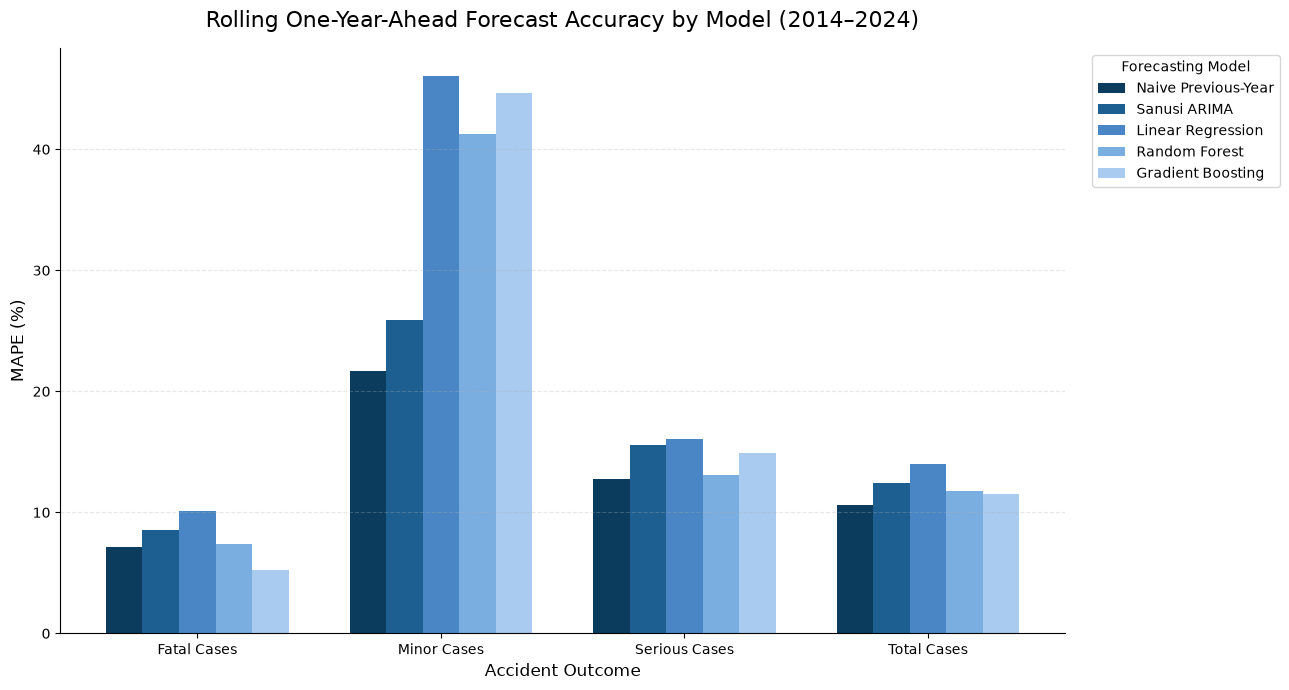

In [148]:
import matplotlib.pyplot as plt
import numpy as np


outcome_order = [
    "Fatal Cases",
    "Minor Cases",
    "Serious Cases",
    "Total Cases"
]

model_order = [
    "Naive Previous-Year",
    "Sanusi ARIMA",
    "Linear Regression",
    "Random Forest",
    "Gradient Boosting"
]

# Blue colour scale: dark -> light
blue_palette = [
    "#0B3C5D",  # Naive Previous-Year
    "#1D5F91",  # Sanusi ARIMA
    "#4A86C5",  # Linear Regression
    "#7AADE0",  # Random Forest
    "#A9CBEF"   # Gradient Boosting
]


plot_df = final_model_comparison.copy()


plot_df["Model_Plot"] = plot_df["Model"].replace({
    "Sanusi ARIMA(0, 1, 1)": "Sanusi ARIMA",
    "Sanusi ARIMA(1, 1, 1)": "Sanusi ARIMA",
    "Sanusi ARIMA(1, 1, 0)": "Sanusi ARIMA"
})


x = np.arange(len(outcome_order))
width = 0.15

fig, ax = plt.subplots(figsize=(13, 7))

for i, model in enumerate(model_order):

    values = []

    for outcome in outcome_order:
        value = plot_df.loc[
            (plot_df["Outcome"] == outcome) &
            (plot_df["Model_Plot"] == model),
            "MAPE (%)"
        ]

        values.append(value.iloc[0] if len(value) > 0 else np.nan)

    ax.bar(
        x + (i - 2) * width,
        values,
        width,
        label=model,
        color=blue_palette[i]
    )

# Labels and title
ax.set_title(
    "Rolling One-Year-Ahead Forecast Accuracy by Model (2014–2024)",
    fontsize=16,
    pad=15
)

ax.set_xlabel("Accident Outcome", fontsize=12)
ax.set_ylabel("MAPE (%)", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(outcome_order)


ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


ax.legend(
    title="Forecasting Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Rolling One-Year-Ahead Forecast Accuracy (2014–2024)

The figure compares the Mean Absolute Percentage Error (MAPE) of the forecasting models using the same expanding-window one-year-ahead evaluation approach for 2014–2024. Lower MAPE values indicate better forecasting accuracy.

The results show differences in model performance across the four road traffic crash categories. For Fatal Cases, Gradient Boosting achieved the lowest MAPE of 5.26%. The naïve previous-year benchmark performed better for Minor Cases and Total Cases, recording MAPEs of 21.64% and 10.61%, respectively. Similarly, the naïve benchmark achieved the lowest MAPE of 12.72% for Serious Cases, although Random Forest recorded a lower RMSE in the corresponding forecasting comparison.

Overall, the findings indicate that no single forecasting model consistently performed better across all crash categories. While the ARIMA models used by Sanusi et al. (2016) remained competitive for some outcomes, they did not consistently outperform the naïve benchmark or the machine-learning models over the 2014–2024 evaluation period.

### Comparison of Relative Forecast Accuracy

The MAPE comparison further shows that forecasting accuracy varied across the different road traffic crash categories. Gradient Boosting achieved the lowest percentage error for Fatal Cases, while the naïve previous-year benchmark recorded the lowest MAPE among the five main models for Minor, Serious and Total Cases.

The higher percentage errors recorded by the machine-learning models for Minor Cases suggest that their forecasting accuracy may be influenced by the characteristics of the crash category being predicted.

Overall, the findings indicate that no single forecasting approach consistently performed better across all four crash categories.

In [163]:
%whos DataFrame

Variable                       Type         Data/Info
-----------------------------------------------------
actual                         DataFrame    Shape: (11, 2)
arima_sensitivity_comparison   DataFrame    Shape: (8, 5)
df                             DataFrame    Shape: (65, 8)
extended_df                    DataFrame    Shape: (65, 8)
final_model_comparison         DataFrame    Shape: (20, 5)
final_table                    DataFrame    Shape: (20, 5)
gb_results                     DataFrame    Shape: (44, 8)
gb_summary                     DataFrame    Shape: (4, 5)
lr_results                     DataFrame    Shape: (44, 8)
lr_summary                     DataFrame    Shape: (4, 5)
mape_plot                      DataFrame    Shape: (4, 5)
ml_annual                      DataFrame    Shape: (65, 17)
model_data                     DataFrame    Shape: (11, 8)
naive_results                  DataFrame    Shape: (44, 8)
naive_summary                  DataFrame    Shape: (4, 5)
plot_data  

In [165]:
sanusi_arima_results.head()

,Year,Actual,Forecast,Error,Absolute_Error,APE,Outcome,Model
0,2014,907,1804.774044,-897.774044,897.774044,98.982805,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
1,2015,841,1056.245720,-215.245720,215.245720,25.594021,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
2,2016,1423,789.132298,633.867702,633.867702,44.544463,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
3,2017,1340,1302.541026,37.458974,37.458974,2.795446,Minor Cases,"Sanusi ARIMA(1, 1, 1)"
4,2018,1153,1415.899975,-262.899975,262.899975,22.801386,Minor Cases,"Sanusi ARIMA(1, 1, 1)"


In [167]:
rolling_predictions = pd.concat([
    naive_results,
    sanusi_arima_results,
    lr_results,
    rf_results,
    gb_results
], ignore_index=True)

print(rolling_predictions.shape)
rolling_predictions.head()

(220, 8)


,Year,Actual,Forecast,Error,Absolute_Error,APE,Outcome,Model
0,2014,907,1700.0,-793.0,793.0,87.431092,Minor Cases,Naive Previous-Year
1,2015,841,907.0,-66.0,66.0,7.847800,Minor Cases,Naive Previous-Year
2,2016,1423,841.0,582.0,582.0,40.899508,Minor Cases,Naive Previous-Year
3,2017,1340,1423.0,-83.0,83.0,6.194030,Minor Cases,Naive Previous-Year
4,2018,1153,1340.0,-187.0,187.0,16.218560,Minor Cases,Naive Previous-Year


In [169]:
rolling_predictions["Model"] = rolling_predictions["Model"].replace({
    "Sanusi_ARIMA(1,1,1)": "Sanusi ARIMA",
    "Sanusi_ARIMA(1,1,0)": "Sanusi ARIMA",
    "Sanusi_ARIMA(0,1,1)": "Sanusi ARIMA"
})

In [171]:
rolling_predictions.groupby(["Outcome", "Model"]).size()

Outcome        Model                
Fatal Cases    Gradient Boosting        11
               Linear Regression        11
               Naive Previous-Year      11
               Random Forest            11
               Sanusi ARIMA(0, 1, 1)    11
Minor Cases    Gradient Boosting        11
               Linear Regression        11
               Naive Previous-Year      11
               Random Forest            11
               Sanusi ARIMA(1, 1, 1)    11
Serious Cases  Gradient Boosting        11
               Linear Regression        11
               Naive Previous-Year      11
               Random Forest            11
               Sanusi ARIMA(1, 1, 0)    11
Total Cases    Gradient Boosting        11
               Linear Regression        11
               Naive Previous-Year      11
               Random Forest            11
               Sanusi ARIMA(1, 1, 1)    11
dtype: int64

In [173]:
# Standardise all Sanusi ARIMA labels for plotting
rolling_predictions.loc[
    rolling_predictions["Model"].str.startswith("Sanusi ARIMA"),
    "Model"
] = "Sanusi ARIMA"

# Check
rolling_predictions.groupby(["Outcome", "Model"]).size()

Outcome        Model              
Fatal Cases    Gradient Boosting      11
               Linear Regression      11
               Naive Previous-Year    11
               Random Forest          11
               Sanusi ARIMA           11
Minor Cases    Gradient Boosting      11
               Linear Regression      11
               Naive Previous-Year    11
               Random Forest          11
               Sanusi ARIMA           11
Serious Cases  Gradient Boosting      11
               Linear Regression      11
               Naive Previous-Year    11
               Random Forest          11
               Sanusi ARIMA           11
Total Cases    Gradient Boosting      11
               Linear Regression      11
               Naive Previous-Year    11
               Random Forest          11
               Sanusi ARIMA           11
dtype: int64

### actual vs rolling forecast plots

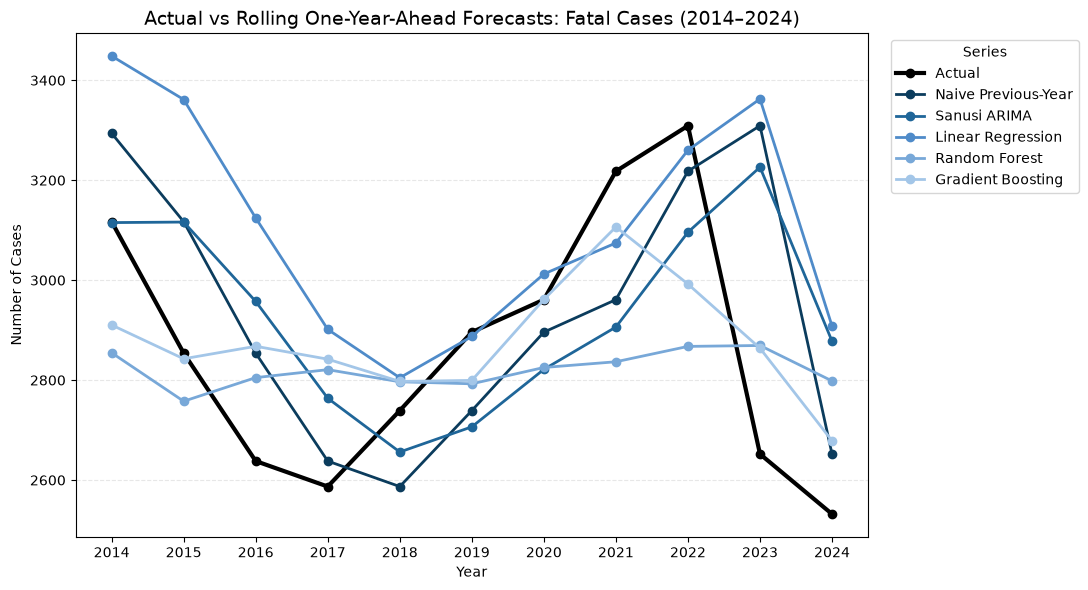

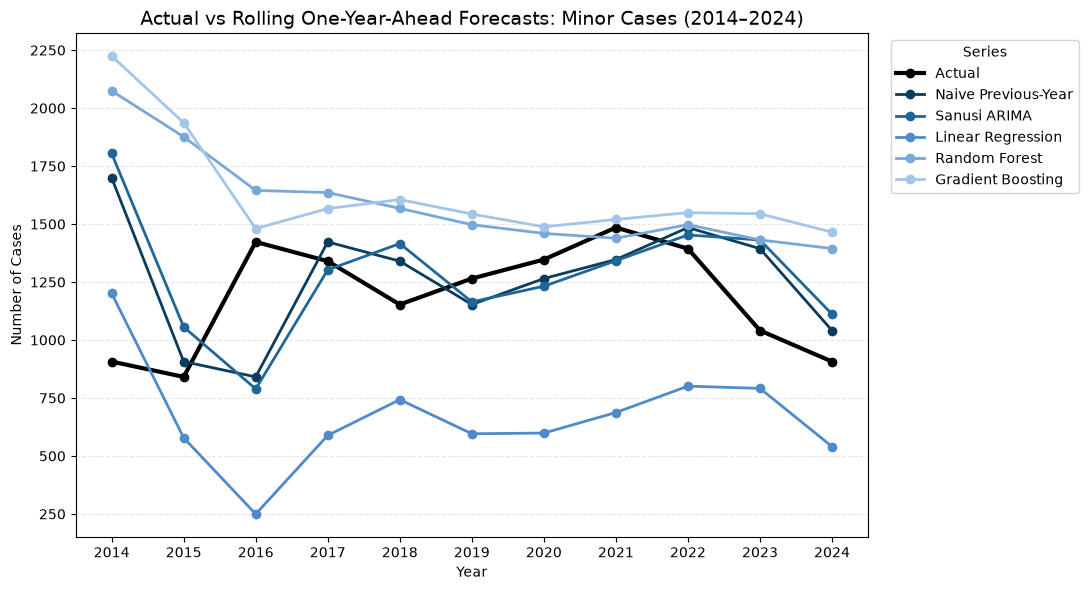

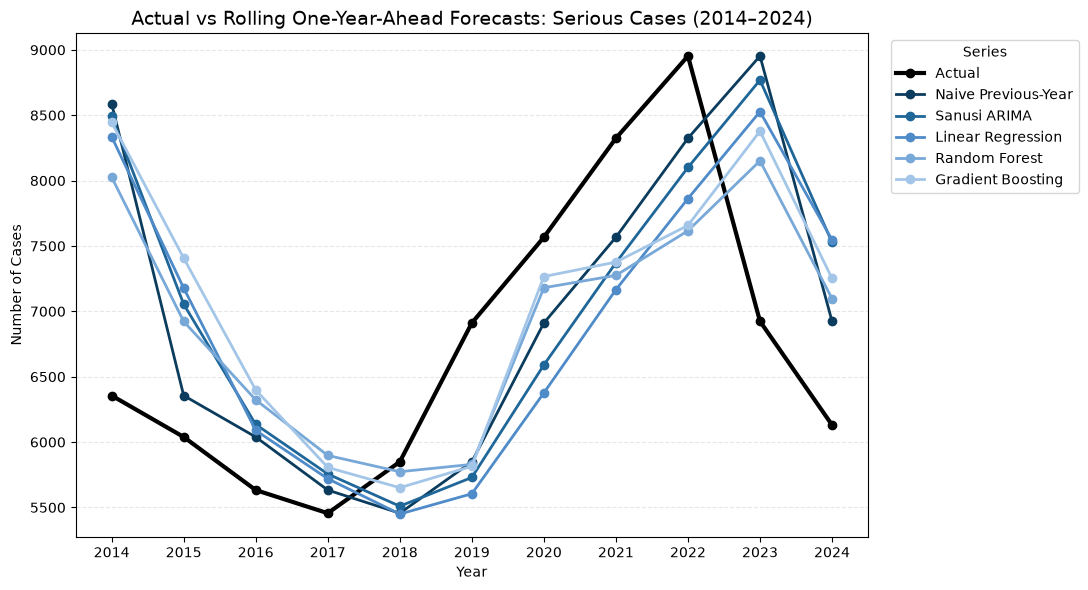

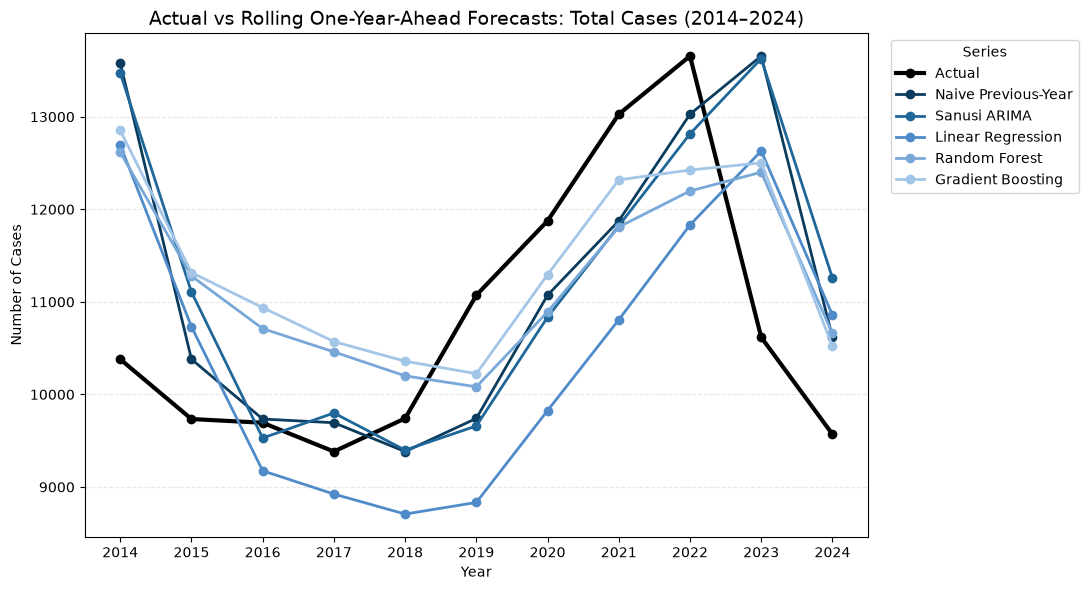

In [175]:
import matplotlib.pyplot as plt

# Blue colour scale used in the MAPE chart
model_colors = {
    "Naive Previous-Year": "#0B3C5D",
    "Sanusi ARIMA": "#1F6699",
    "Linear Regression": "#4F8BC9",
    "Random Forest": "#78A8D8",
    "Gradient Boosting": "#A3C6E8"
}

outcomes = [
    "Fatal Cases",
    "Minor Cases",
    "Serious Cases",
    "Total Cases"
]

for outcome in outcomes:

    subset = rolling_predictions[
        rolling_predictions["Outcome"] == outcome
    ].copy()

    plt.figure(figsize=(11, 6))

    # Actual values - only need one copy per year
    actual = (
        subset[["Year", "Actual"]]
        .drop_duplicates()
        .sort_values("Year")
    )

    plt.plot(
        actual["Year"],
        actual["Actual"],
        marker="o",
        linewidth=3,
        label="Actual",
        color="black"
    )

    # Forecast from each model
    for model, color in model_colors.items():

        model_data = (
            subset[subset["Model"] == model]
            .sort_values("Year")
        )

        plt.plot(
            model_data["Year"],
            model_data["Forecast"],
            marker="o",
            linewidth=2,
            label=model,
            color=color
        )

    plt.title(
        f"Actual vs Rolling One-Year-Ahead Forecasts: {outcome} (2014–2024)",
        fontsize=14
    )

    plt.xlabel("Year")
    plt.ylabel("Number of Cases")

    plt.xticks(range(2014, 2025))
    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.legend(
        title="Series",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

### Actual versus Rolling One-Year-Ahead Forecasts

The figures compare the actual annual road traffic crash figures with the one-year-ahead forecasts generated by the naïve previous-year benchmark, the ARIMA models used by Sanusi et al. (2016), Linear Regression, Random Forest and Gradient Boosting over the 2014–2024 evaluation period.

The results show differences in forecasting accuracy across the four crash categories. For Fatal Cases, the model predictions generally followed the observed values more closely than for the other categories, with Gradient Boosting showing particularly close agreement with the actual figures. Minor Cases were more difficult to predict, as several models recorded noticeable differences between the forecast and actual values. For Serious and Total Cases, the models captured some of the overall trends but produced larger errors during years with significant changes in crash counts.

The figures also show that forecasting accuracy varied across the evaluation period. Years with larger increases or decreases in crash counts generally showed greater differences between the actual and predicted values.

This highlights the importance of using rolling one-year-ahead forecasting to evaluate model performance, as overall error metrics such as MAE, RMSE and MAPE do not fully show when forecasting errors occurred or how well the models responded to changes in the historical data.

### Absolute forecast errors by year

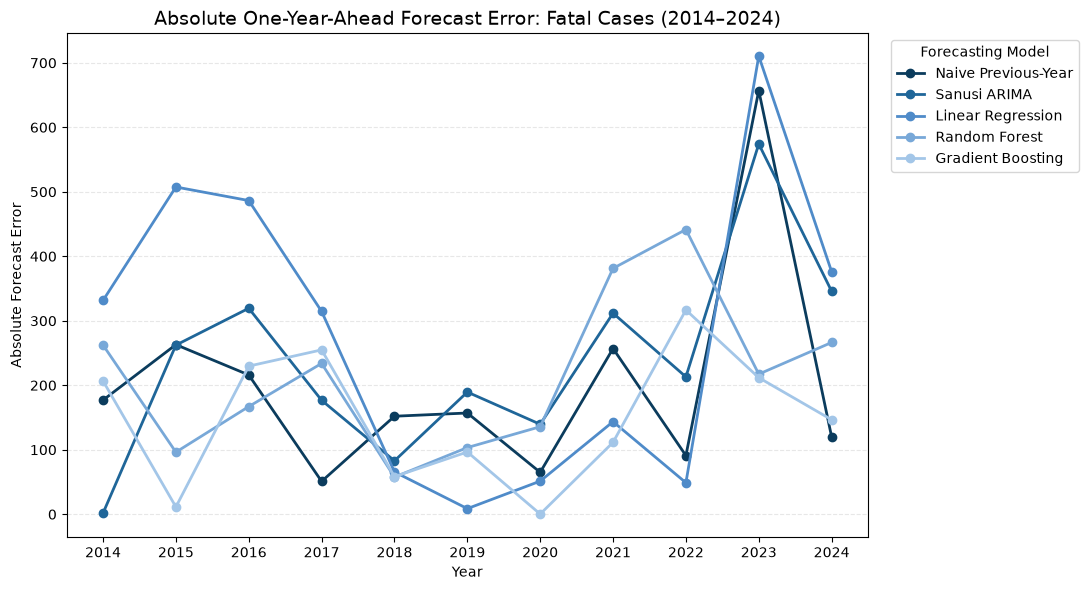

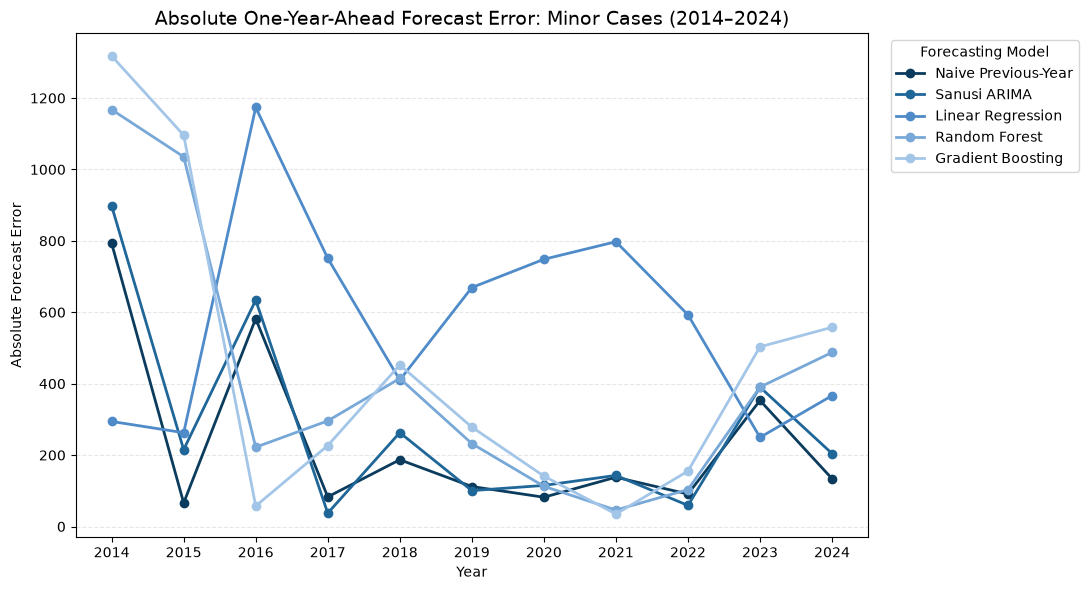

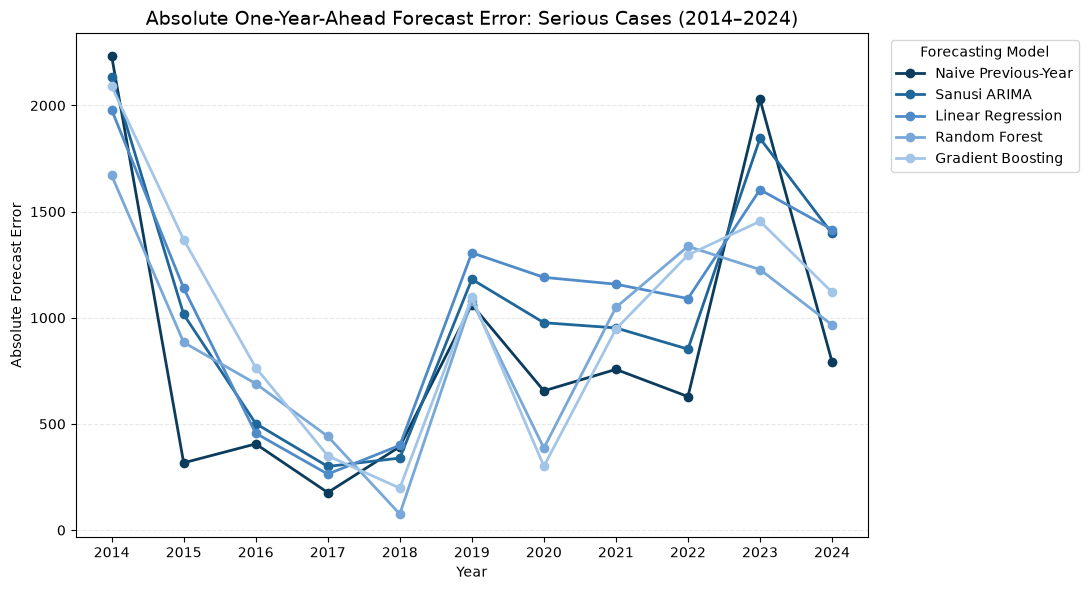

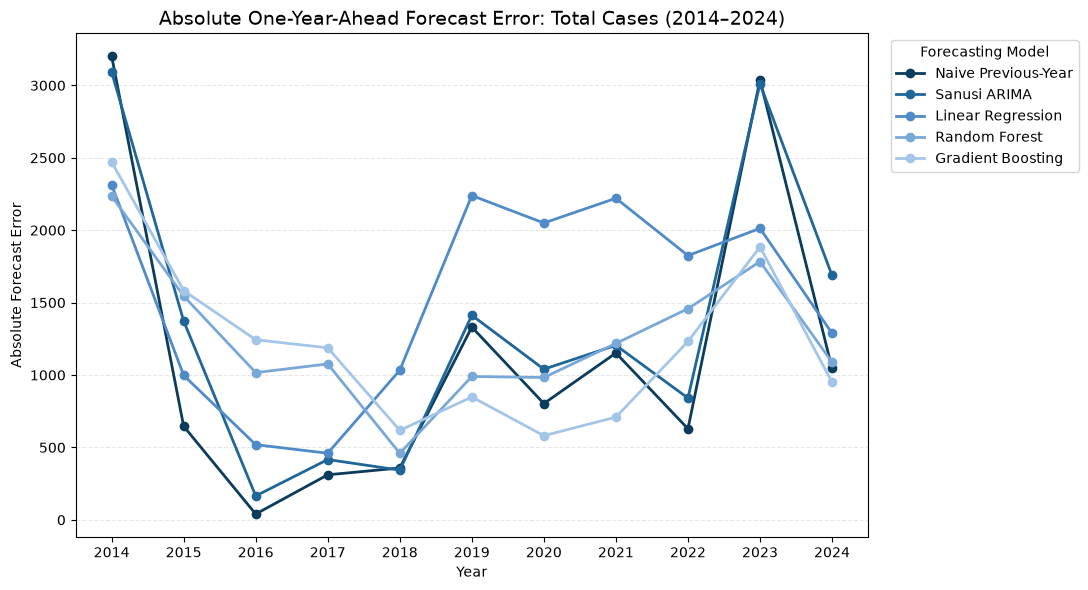

In [177]:
# Calculate absolute forecast error
rolling_predictions["Absolute_Error"] = abs(
    rolling_predictions["Actual"] - rolling_predictions["Forecast"]
)

outcomes = [
    "Fatal Cases",
    "Minor Cases",
    "Serious Cases",
    "Total Cases"
]

model_colors = {
    "Naive Previous-Year": "#0B3C5D",
    "Sanusi ARIMA": "#1F6699",
    "Linear Regression": "#4F8BC9",
    "Random Forest": "#78A8D8",
    "Gradient Boosting": "#A3C6E8"
}

for outcome in outcomes:

    subset = rolling_predictions[
        rolling_predictions["Outcome"] == outcome
    ].copy()

    plt.figure(figsize=(11, 6))

    for model, color in model_colors.items():

        model_data = (
            subset[subset["Model"] == model]
            .sort_values("Year")
        )

        plt.plot(
            model_data["Year"],
            model_data["Absolute_Error"],
            marker="o",
            linewidth=2,
            label=model,
            color=color
        )

    plt.title(
        f"Absolute One-Year-Ahead Forecast Error: {outcome} (2014–2024)",
        fontsize=14
    )

    plt.xlabel("Year")
    plt.ylabel("Absolute Forecast Error")

    plt.xticks(range(2014, 2025))

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    plt.legend(
        title="Forecasting Model",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

In [191]:
final_table = final_model_comparison.copy()

final_table[["MAE", "RMSE", "MAPE (%)"]] = (
    final_table[["MAE", "RMSE", "MAPE (%)"]].round(2)
)

final_table

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Fatal Cases,Gradient Boosting,149.50,179.00,5.26
1,Fatal Cases,Random Forest,214.80,243.39,7.39
2,Fatal Cases,Naive Previous-Year,200.55,256.22,7.13
3,Fatal Cases,"Sanusi ARIMA(0, 1, 1)",237.90,278.98,8.54
4,Fatal Cases,Linear Regression,276.81,354.12,10.09
5,Minor Cases,Naive Previous-Year,238.27,330.69,21.64
6,Minor Cases,"Sanusi ARIMA(1, 1, 1)",278.16,377.32,25.92
7,Minor Cases,Random Forest,409.82,540.51,41.27
8,Minor Cases,Gradient Boosting,438.28,594.22,44.69
9,Minor Cases,Linear Regression,574.19,636.58,46.08


### Final Model Comparison

The table presents the final comparison of the forecasting accuracy of the naïve previous-year benchmark, the ARIMA models used by Sanusi et al. (2016), Linear Regression, Random Forest and Gradient Boosting. All models were evaluated using the same expanding-window one-year-ahead forecasting approach for 2014–2024 to ensure a consistent comparison.

Forecasting performance was assessed using three evaluation metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and Mean Absolute Percentage Error (MAPE). Lower values indicate better forecasting accuracy. MAE measures the average difference between the actual and predicted values, regardless of direction, while RMSE gives greater weight to larger forecasting errors. MAPE measures the average forecast error as a percentage of the actual values.

### Comparison by Accident Outcome

**Fatal Cases**

Gradient Boosting achieved the best overall forecasting accuracy for Fatal Cases, recording the lowest MAE of 149.50, RMSE of 179.00 and MAPE of 5.26%. Random Forest also performed relatively well, although the naïve previous-year benchmark recorded slightly lower MAE and MAPE values. In comparison, the original ARIMA(0,1,1) model used by Sanusi et al. (2016) produced an MAE of 237.90, RMSE of 278.98 and MAPE of 8.54%. These findings show that Gradient Boosting provided more accurate forecasts for Fatal Cases over the 2014–2024 evaluation period.

**Minor Cases**

The machine-learning models recorded higher forecasting errors for Minor Cases. The naïve previous-year benchmark achieved the lowest MAE of 238.27 and RMSE of 330.69 among the five main models, with a MAPE of 21.64%. The original ARIMA(1,1,1) model also performed considerably better than Linear Regression, Random Forest and Gradient Boosting. This suggests that using more complex machine-learning models did not improve forecasting accuracy for Minor Cases during the evaluation period.

**Serious Cases**

For Serious Cases, the best-performing model varied depending on the evaluation metric. Random Forest achieved the lowest RMSE of 995.27, indicating that it performed better when larger forecasting errors were given greater weight. However, the naïve previous-year benchmark recorded the lowest MAE of 859.27 and MAPE of 12.72%. Random Forest achieved an MAE of 891.78 and MAPE of 13.12%. These results indicate that neither model consistently performed better across all three evaluation metrics.

**Total Cases**

A similar pattern was observed for Total Cases. The naïve previous-year benchmark achieved the lowest MAE of 1,141.73 and MAPE of 10.61%, while Gradient Boosting recorded the lowest RMSE of 1,330.91. Random Forest followed closely with an RMSE of 1,338.69.

In comparison, the original ARIMA(1,1,1) model recorded an MAE of 1,326.17, RMSE of 1,621.46 and MAPE of 12.41%.

These findings suggest that the machine-learning models, particularly Gradient Boosting and Random Forest, were more effective at reducing larger forecasting errors for Total Cases. However, they did not consistently outperform the simpler naïve benchmark across all three evaluation metrics.

### Sensitivity of the ARIMA Specifications

The updated ARIMA specifications identified using the extended historical dataset did not consistently perform better than the original models used by Sanusi et al. (2016).

For Fatal Cases, the ARIMA(0,1,1) specification remained unchanged. For Serious Cases, the updated ARIMA(1,1,1) model achieved slightly lower forecasting errors than the original ARIMA(1,1,0) model. However, for Minor and Total Cases, the updated specifications did not consistently improve forecasting accuracy compared with the original models.

Overall, these findings suggest that updating the ARIMA model specifications using additional historical data does not necessarily lead to more accurate one-year-ahead forecasts.

The original ARIMA models used by Sanusi et al. (2016) therefore remain useful benchmarks for comparing the performance of the alternative forecasting approaches.

However, because the updated specifications were selected using the complete historical dataset, the results should be interpreted as a retrospective sensitivity analysis rather than a fully independent out-of-sample model-selection exercise.

## Summary of Annual Forecasting Results

The annual forecasting analysis reproduced and extended the ARIMA approach used by Sanusi et al. (2016) and compared the original ARIMA models with the naïve previous-year benchmark and three machine-learning models: Linear Regression, Random Forest and Gradient Boosting. All models were evaluated using the same expanding-window one-year-ahead forecasting approach for 2014–2024 to ensure a consistent comparison.

The results show that no single forecasting model consistently performed better across all four road traffic crash categories and evaluation metrics. For Fatal Cases, Gradient Boosting achieved the best overall forecasting accuracy, recording the lowest MAE, RMSE and MAPE. For Serious Cases, Random Forest achieved the lowest RMSE, while the naïve previous-year benchmark recorded the lowest MAE and MAPE. A similar pattern was observed for Total Cases, where Gradient Boosting achieved the lowest RMSE, but the naïve benchmark performed better based on MAE and MAPE.

For Minor Cases, the results were different. The naïve benchmark and the original ARIMA model performed considerably better than the three machine-learning models. This suggests that using more complex forecasting approaches does not necessarily lead to better predictions, particularly for this crash category.

An important finding from the analysis was the strong performance of the naïve previous-year benchmark. Despite its simplicity, it achieved lower forecasting errors than several of the statistical and machine-learning models. This highlights the importance of including a simple benchmark when evaluating forecasting accuracy, rather than assuming that more complex models will automatically produce better results.

The analysis also showed that updating the ARIMA specifications using the extended historical dataset did not consistently improve forecasting accuracy compared with the original models used by Sanusi et al. (2016). However, because the updated specifications were identified using the complete historical series, these results were treated as a retrospective sensitivity analysis.

Overall, the findings provide partial support for the use of machine-learning models in forecasting road traffic crash trends in Nigeria. While machine-learning approaches improved forecasting accuracy for some crash categories and evaluation metrics, these improvements were not consistent across all outcomes.

The results therefore do not provide sufficient evidence to conclude that machine-learning models consistently outperform traditional ARIMA models or simpler forecasting benchmarks when applied to nationally aggregated annual road traffic crash data.

### Link to the State-Quarter Forecasting Analysis

The annual forecasting analysis allowed for a direct comparison with the ARIMA approach used by Sanusi et al. (2016). However, using nationally aggregated annual data limits the number of observations and does not capture differences between states or changes within each year.

The main forecasting analysis therefore focused on state-quarter road traffic crash data, allowing differences across states and quarters to be examined. This dataset also included lagged crash-cause variables as additional predictors for the machine-learning models.

The annual and state-quarter forecasting results were not directly compared because the datasets differed in their time periods, forecasting horizons, data structures and available predictors.

Instead, the annual analysis served as a reproduction and extension of the approach used by Sanusi et al. (2016), while the state-quarter analysis examined the performance of machine-learning models using a more detailed and recent dataset.